# Task 3 - Static vs Contextual Embeddings

This notebook compares static GloVe embeddings with contextual BERT embeddings. Static embeddings give one vector per word. Contextual embeddings can change when the same word appears in a different sentence.

## Notebook Settings

Environment and task variables used in this notebook:

- `GLOVE_MODEL_NAME = "glove-wiki-gigaword-100"`
- `BERT_MODEL_NAME = "bert-base-uncased"`
- `STATIC_WORDS = ["bank", "apple", "light"]`
- `ANALOGY_POSITIVE_WORDS = ["king", "woman"]`
- `ANALOGY_NEGATIVE_WORDS = ["man"]`
- `TOP_N = 5`
- `SEED = 42`

The first run may download the GloVe vectors and BERT model. The notebook uses CPU only.

## Setup

In [1]:
from pathlib import Path
from IPython.display import Image, display
import random
import sys

import gensim.downloader as api
import numpy as np
import pandas as pd
import torch
from transformers import AutoModel, AutoTokenizer

/home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)
pd.set_option("display.max_columns", None)

In [3]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [4]:
from src.config import METADATA_DIR, PLOTS_DIR, SEED, TABLES_DIR
from src.embedding_utils import (
    compute_cosine_similarity,
    get_contextual_word_embedding,
    get_static_neighbors,
    project_embeddings_to_2d,
    run_static_analogy,
)
from src.plotting import save_embedding_projection_plot
from src.result_saver import save_dataframe, save_json

In [5]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [6]:
for output_dir in [METADATA_DIR, PLOTS_DIR, TABLES_DIR]:
    output_dir.mkdir(parents=True, exist_ok=True)

## Load Static GloVe Embeddings

GloVe is static: each word has one vector, no matter which sentence it appears in.

In [7]:
GLOVE_MODEL_NAME = "glove-wiki-gigaword-100"
TOP_N = 5

In [8]:
GLOVE_MODEL_NAME, TOP_N

('glove-wiki-gigaword-100', 5)

In [9]:
w2v = api.load(GLOVE_MODEL_NAME)

In [10]:
print("vector size:", w2v.vector_size)
print("vocabulary size:", len(w2v))

vector size: 100
vocabulary size: 400000


## Static Nearest Neighbors

In [11]:
STATIC_WORDS = ["bank", "apple", "light"]

In [12]:
STATIC_WORDS

['bank', 'apple', 'light']

In [13]:
neighbor_rows = []

for word in STATIC_WORDS:
    neighbors = get_static_neighbors(
        model=w2v,
        word=word,
        top_n=TOP_N,
    )
    for rank, neighbor in enumerate(neighbors, start=1):
        neighbor_rows.append({
            "word": word,
            "rank": rank,
            "neighbor": neighbor["word"],
            "similarity": neighbor["similarity"],
        })

In [14]:
glove_neighbors_df = pd.DataFrame(neighbor_rows)

In [15]:
glove_neighbors_df

,word,rank,neighbor,similarity
0,bank,1,banks,0.805713
1,bank,2,banking,0.753071
2,bank,3,credit,0.703760
3,bank,4,investment,0.693994
4,bank,5,financial,0.677741
5,apple,1,microsoft,0.744941
6,apple,2,ibm,0.682164
7,apple,3,intel,0.677809
8,apple,4,software,0.677542
9,apple,5,dell,0.674144


In [16]:
save_dataframe(
    dataframe=glove_neighbors_df,
    output_path=TABLES_DIR / "task3_glove_neighbors.csv",
)

**Observation:** This table shows one fixed neighborhood for each word. For example, `bank` has one list of neighbors even though it can mean a river edge or a financial company.

## Static Analogy

In [17]:
ANALOGY_POSITIVE_WORDS = ["king", "woman"]
ANALOGY_NEGATIVE_WORDS = ["man"]

In [18]:
ANALOGY_POSITIVE_WORDS, ANALOGY_NEGATIVE_WORDS

(['king', 'woman'], ['man'])

In [19]:
static_analogy = run_static_analogy(
    model=w2v,
    positive_words=ANALOGY_POSITIVE_WORDS,
    negative_words=ANALOGY_NEGATIVE_WORDS,
    top_n=TOP_N,
)

In [20]:
static_analogy_df = pd.DataFrame(static_analogy)

In [21]:
static_analogy_df

,word,similarity
0,queen,0.769854
1,monarch,0.684338
2,throne,0.675574
3,daughter,0.659456
4,princess,0.652053


**Observation:** The analogy uses vector math: `king - man + woman`. If `queen` appears near the top, the static vectors captured a common gender/royalty pattern.

## Load BERT For Contextual Embeddings

BERT is contextual: the vector for a word can change when the sentence changes.

In [22]:
BERT_MODEL_NAME = "bert-base-uncased"

In [23]:
BERT_MODEL_NAME

'bert-base-uncased'

In [24]:
bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
bert_model = AutoModel.from_pretrained(
    BERT_MODEL_NAME,
    output_hidden_states=True,
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4127.78it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [25]:
print(type(bert_tokenizer).__name__)
print(type(bert_model).__name__)
print("hidden size:", bert_model.config.hidden_size)

BertTokenizer
BertModel
hidden size: 768


## Bank In Two Contexts

In [26]:
bank_river_sentence = "I sat by the river bank and watched the water."
bank_money_sentence = "I deposited money at the bank this morning."

In [27]:
bank_river_sentence, bank_money_sentence

('I sat by the river bank and watched the water.',
 'I deposited money at the bank this morning.')

In [28]:
bank_river_vector = get_contextual_word_embedding(
    sentence=bank_river_sentence,
    word="bank",
    tokenizer=bert_tokenizer,
    model=bert_model,
)

In [29]:
bank_money_vector = get_contextual_word_embedding(
    sentence=bank_money_sentence,
    word="bank",
    tokenizer=bert_tokenizer,
    model=bert_model,
)

In [30]:
bank_river_vector.shape, bank_money_vector.shape

((768,), (768,))

In [31]:
bank_bert_similarity = compute_cosine_similarity(
    first_vector=bank_river_vector,
    second_vector=bank_money_vector,
)

In [32]:
bank_bert_similarity

0.5164129137992859

In [33]:
bank_static_similarity = compute_cosine_similarity(
    first_vector=w2v["bank"],
    second_vector=w2v["bank"],
)

In [34]:
bank_static_similarity

1.0

**Observation:** The static similarity for `bank` is exactly the same word compared with itself, so it is 1.0. The BERT similarity compares two sentence-specific vectors, so it can show that river `bank` and money `bank` are not used the same way.

## More Contextual Comparisons

In [35]:
polysemy_examples = [
    {
        "word": "light",
        "sentence_a": "The lamp gave a soft light in the room.",
        "sentence_b": "This suitcase is light enough to carry.",
        "meaning_a": "brightness",
        "meaning_b": "weight",
    },
    {
        "word": "match",
        "sentence_a": "The tennis match lasted three hours.",
        "sentence_b": "The match lit the candle quickly.",
        "meaning_a": "sports",
        "meaning_b": "fire",
    },
]

In [36]:
pd.DataFrame(polysemy_examples)

,word,sentence_a,sentence_b,meaning_a,meaning_b
0,light,The lamp gave a soft light in the room.,This suitcase is light enough to carry.,brightness,weight
1,match,The tennis match lasted three hours.,The match lit the candle quickly.,sports,fire


In [37]:
context_rows = []

for example in polysemy_examples:
    vector_a = get_contextual_word_embedding(
        sentence=example["sentence_a"],
        word=example["word"],
        tokenizer=bert_tokenizer,
        model=bert_model,
    )
    vector_b = get_contextual_word_embedding(
        sentence=example["sentence_b"],
        word=example["word"],
        tokenizer=bert_tokenizer,
        model=bert_model,
    )
    similarity = compute_cosine_similarity(
        first_vector=vector_a,
        second_vector=vector_b,
    )
    context_rows.append({
        "word": example["word"],
        "meaning_a": example["meaning_a"],
        "meaning_b": example["meaning_b"],
        "bert_similarity": similarity,
    })

In [38]:
contextual_similarity_df = pd.DataFrame(context_rows)

In [39]:
contextual_similarity_df

,word,meaning_a,meaning_b,bert_similarity
0,light,brightness,weight,0.467272
1,match,sports,fire,0.343003


## Similarity Comparison Table

In [40]:
similarity_rows = [
    {
        "setting": "GloVe static",
        "word": "bank",
        "cosine_similarity": bank_static_similarity,
        "interpretation": "Same word uses the same vector, so similarity is 1.0.",
    },
    {
        "setting": "BERT contextual",
        "word": "bank",
        "cosine_similarity": bank_bert_similarity,
        "interpretation": "The river and money meanings get different sentence vectors.",
    },
]

for row in context_rows:
    similarity_rows.append({
        "setting": "BERT contextual",
        "word": row["word"],
        "cosine_similarity": row["bert_similarity"],
        "interpretation": f"Compared {row['meaning_a']} vs {row['meaning_b']} meanings.",
    })

In [41]:
similarity_comparison_df = pd.DataFrame(similarity_rows)

In [42]:
similarity_comparison_df

,setting,word,cosine_similarity,interpretation
0,GloVe static,bank,1.000000,"Same word uses the same vector, so similarity is 1.0."
1,BERT contextual,bank,0.516413,The river and money meanings get different sentence vectors.
2,BERT contextual,light,0.467272,Compared brightness vs weight meanings.
3,BERT contextual,match,0.343003,Compared sports vs fire meanings.


In [43]:
save_dataframe(
    dataframe=similarity_comparison_df,
    output_path=TABLES_DIR / "task3_similarity_comparison.csv",
)

**Answer:** Static embeddings are cheaper and simpler, but they cannot change the vector when the meaning changes. BERT is more expensive, but it can represent the same word differently in different sentences.

## Contextual Projection Plot

The plot uses ten sentences with the word `light`. PCA reduces each BERT vector to two numbers so we can see whether meanings separate visually.

In [44]:
light_sentences = [
    {"sentence": "The light from the window filled the room.", "meaning": "brightness", "short_label": "bright 1"},
    {"sentence": "A bright light flashed in the dark sky.", "meaning": "brightness", "short_label": "bright 2"},
    {"sentence": "The light above the desk stopped working.", "meaning": "brightness", "short_label": "bright 3"},
    {"sentence": "She turned off the light before sleeping.", "meaning": "brightness", "short_label": "bright 4"},
    {"sentence": "The morning light made the room warm.", "meaning": "brightness", "short_label": "bright 5"},
    {"sentence": "The box was light enough to lift with one hand.", "meaning": "weight", "short_label": "weight 1"},
    {"sentence": "I packed a light jacket for the trip.", "meaning": "weight", "short_label": "weight 2"},
    {"sentence": "The bag felt light after I removed the books.", "meaning": "weight", "short_label": "weight 3"},
    {"sentence": "This laptop is light and easy to carry.", "meaning": "weight", "short_label": "weight 4"},
    {"sentence": "The meal was light but still filling.", "meaning": "weight", "short_label": "weight 5"},
]

In [45]:
light_projection_source_df = pd.DataFrame(light_sentences)

In [46]:
light_projection_source_df

,sentence,meaning,short_label
0,The light from the window filled the room.,brightness,bright 1
1,A bright light flashed in the dark sky.,brightness,bright 2
2,The light above the desk stopped working.,brightness,bright 3
3,She turned off the light before sleeping.,brightness,bright 4
4,The morning light made the room warm.,brightness,bright 5
5,The box was light enough to lift with one hand.,weight,weight 1
6,I packed a light jacket for the trip.,weight,weight 2
7,The bag felt light after I removed the books.,weight,weight 3
8,This laptop is light and easy to carry.,weight,weight 4
9,The meal was light but still filling.,weight,weight 5


In [47]:
light_vectors = []

for item in light_sentences:
    vector = get_contextual_word_embedding(
        sentence=item["sentence"],
        word="light",
        tokenizer=bert_tokenizer,
        model=bert_model,
    )
    light_vectors.append(vector)

In [48]:
light_embedding_matrix = np.vstack(light_vectors)

In [49]:
light_embedding_matrix.shape

(10, 768)

In [50]:
light_coordinates = project_embeddings_to_2d(light_embedding_matrix)

In [51]:
light_coordinates[:3]

array([[ 5.930708 , -2.0993657],
       [ 5.0336843, -2.866387 ],
       [ 3.9498458, -2.5247467]], dtype=float32)

In [52]:
projection_df = light_projection_source_df.copy()
projection_df["x"] = light_coordinates[:, 0]
projection_df["y"] = light_coordinates[:, 1]

In [53]:
projection_df

,sentence,meaning,short_label,x,y
0,The light from the window filled the room.,brightness,bright 1,5.930708,-2.099366
1,A bright light flashed in the dark sky.,brightness,bright 2,5.033684,-2.866387
2,The light above the desk stopped working.,brightness,bright 3,3.949846,-2.524747
3,She turned off the light before sleeping.,brightness,bright 4,5.825307,4.696882
4,The morning light made the room warm.,brightness,bright 5,6.081222,0.568073
5,The box was light enough to lift with one hand.,weight,weight 1,-5.462028,-3.451518
6,I packed a light jacket for the trip.,weight,weight 2,-3.824920,8.597493
7,The bag felt light after I removed the books.,weight,weight 3,-6.352525,-1.490887
8,This laptop is light and easy to carry.,weight,weight 4,-7.152269,-1.549057
9,The meal was light but still filling.,weight,weight 5,-4.029011,0.119513


In [54]:
save_embedding_projection_plot(
    dataframe=projection_df,
    x_column="x",
    y_column="y",
    label_column="meaning",
    text_column="short_label",
    title="Task 3 BERT Contextual Embeddings For 'light'",
    output_path=PLOTS_DIR / "task3_contextual_embedding_projection.png",
)

In [55]:
print("saved plot:", PLOTS_DIR / "task3_contextual_embedding_projection.png")

saved plot: /home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/results/plots/task3_contextual_embedding_projection.png


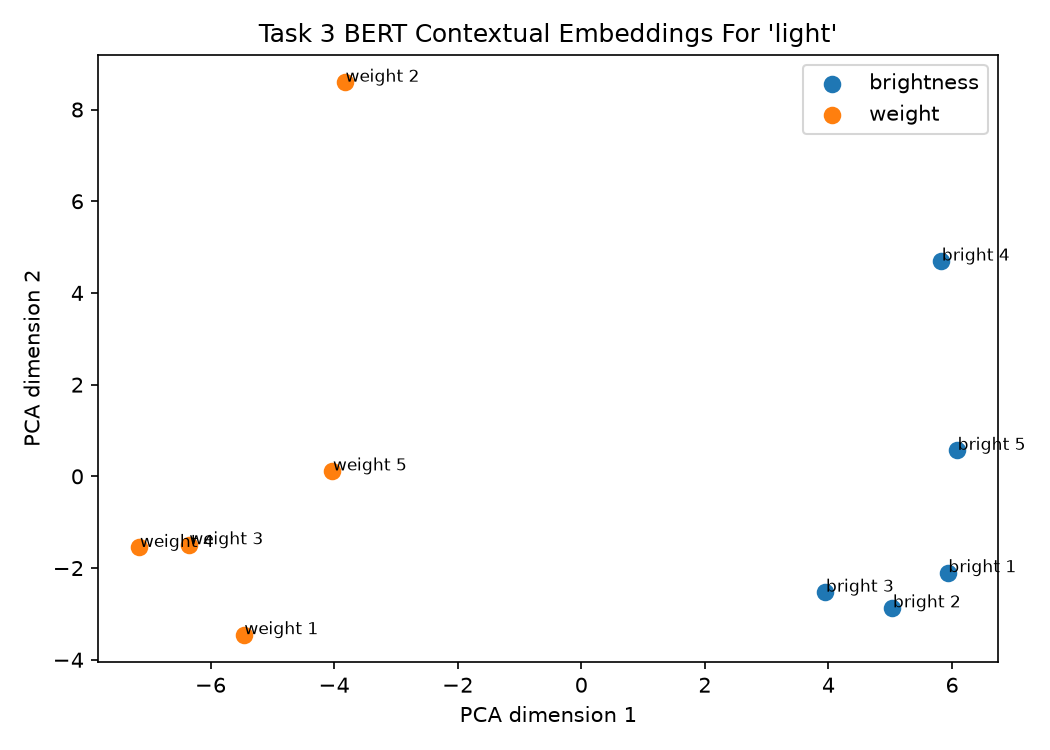

In [56]:
# task3_projection_display
display(Image(filename=str(PLOTS_DIR / "task3_contextual_embedding_projection.png")))


<!-- task3_projection_answer -->
**Answer: Do the senses cluster?**

Mostly yes. In the PCA plot, the brightness uses of `light` mostly appear on the right side, while the weight uses mostly appear on the left side. The split is not perfect because this is only a small set of ten sentences, but the plot does show that BERT changes the word vector when `light` means brightness versus when it means low weight.

## Save Summary

In [57]:
task3_summary = {
    "task": "Task 3 - Static vs Contextual Embeddings",
    "glove_model": GLOVE_MODEL_NAME,
    "bert_model": BERT_MODEL_NAME,
    "static_words": STATIC_WORDS,
    "analogy": "king - man + woman",
    "bank_static_similarity": float(bank_static_similarity),
    "bank_bert_similarity": float(bank_bert_similarity),
    "extra_contextual_words": contextual_similarity_df.to_dict("records"),
    "projection_word": "light",
    "main_result": "Static embeddings use one vector per word, while BERT changes the vector when context changes.",
    "interpretation": "GloVe is simpler and cheaper, but BERT is better when the sentence changes the word meaning.",
}

In [58]:
task3_summary

{'task': 'Task 3 - Static vs Contextual Embeddings',
 'glove_model': 'glove-wiki-gigaword-100',
 'bert_model': 'bert-base-uncased',
 'static_words': ['bank', 'apple', 'light'],
 'analogy': 'king - man + woman',
 'bank_static_similarity': 1.0,
 'bank_bert_similarity': 0.5164129137992859,
 'extra_contextual_words': [{'word': 'light',
   'meaning_a': 'brightness',
   'meaning_b': 'weight',
   'bert_similarity': 0.4672723114490509},
  {'word': 'match',
   'meaning_a': 'sports',
   'meaning_b': 'fire',
   'bert_similarity': 0.34300297498703003}],
 'projection_word': 'light',
 'main_result': 'Static embeddings use one vector per word, while BERT changes the vector when context changes.',
 'interpretation': 'GloVe is simpler and cheaper, but BERT is better when the sentence changes the word meaning.'}

In [59]:
save_json(
    data=task3_summary,
    output_path=METADATA_DIR / "task3_static_contextual_summary.json",
)

## Final Interpretation

Static embeddings are useful when the task is simple, cost matters, and one general meaning per word is enough. Contextual embeddings are better when sentence meaning matters, such as with words like `bank`, `light`, or `match`. In this experiment, GloVe gives one fixed answer for each word, while BERT lets the same word move depending on how it is used.